# CatBoost error analysis

This notebook analyses the chronological CatBoost validation predictions used in `Models_main.ipynb`.

## 1. Load data and reproduce the chronological validation split

This matches `Models_main.ipynb`: the latest 12 approval months are validation and earlier labeled rows are training data.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from catboost import CatBoostRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

ROOT = Path.cwd()
TARGET = "MONTHLY_RENT"
train = pd.read_csv(ROOT / "derived/train_cleaned_enriched.csv")
test = pd.read_csv(ROOT / "derived/test_cleaned_enriched.csv")

approval_dates = pd.to_datetime(train["RENT_APPROVAL_DATE"])
cutoff = approval_dates.max().to_period("M").start_time - pd.DateOffset(months=12)
is_validation = approval_dates > cutoff
training_data = train.loc[~is_validation].copy()
validation_data = train.loc[is_validation].copy()

print(f"Training rows: {len(training_data):,}")
print(f"Validation rows: {len(validation_data):,}")
print(f"Validation period: {validation_data['RENT_APPROVAL_DATE'].min()} to {validation_data['RENT_APPROVAL_DATE'].max()}")

Training rows: 114,683
Validation rows: 35,158
Validation period: 2024-04-01 to 2025-03-01


## 2. Train the CatBoost validation model

This reproduces the CatBoost feature lists, hyperparameters, early stopping, and evaluation setup from `Models_main.ipynb`.

In [2]:
CATBOOST_ALL_FEATURES = [
    "FLOOR_AREA_SQM", "LEASE_COMMENCE_DATE", "HDB_LATITUDE",
    "HDB_LONGITUDE", "HDB_YEAR_COMPLETED", "NEAREST_MRT_KM",
    "NEAREST_SCHOOL_KM", "NEAREST_MALL_KM", "APPROVAL_YEAR",
    "APPROVAL_MONTH", "MONTH_INDEX", "BUILDING_AGE", "TOWN",
    "FLAT_TYPE", "FLAT_MODEL", "HDB_PLANNING_AREA", "LOCATION_KEY",
]
CATBOOST_CATEGORICAL = [
    "TOWN", "FLAT_TYPE", "FLAT_MODEL", "HDB_PLANNING_AREA", "LOCATION_KEY"
]

def make_catboost_features(data):
    return data[CATBOOST_ALL_FEATURES].copy()

# Best CatBoost parameters from Models_FLAML_tuning.ipynb (1094 selected trees).
CB_PARAMS = dict(
    loss_function="RMSE", eval_metric="RMSE", depth=7, learning_rate=0.0718104404496359,
    l2_leaf_reg=10.104124680450155, random_seed=42, thread_count=4, allow_writing_files=False,
)
X_cb_train = make_catboost_features(training_data)
y_cb_train = pd.to_numeric(training_data[TARGET], errors="raise")
X_cb_val = make_catboost_features(validation_data)
y_cb_val = pd.to_numeric(validation_data[TARGET], errors="raise")

catboost_validation_model = CatBoostRegressor(iterations=1094, **CB_PARAMS)
catboost_validation_model.fit(
    X_cb_train, y_cb_train, cat_features=CATBOOST_CATEGORICAL,
    eval_set=(X_cb_val, y_cb_val), early_stopping_rounds=100,
    use_best_model=True, verbose=200,
)
cb_val_predictions = catboost_validation_model.predict(X_cb_val)
cb_best_iterations = catboost_validation_model.tree_count_

print(f"Selected trees: {cb_best_iterations}")
print(f"Validation MAE: {mean_absolute_error(y_cb_val, cb_val_predictions):,.2f}")
print(f"Validation RMSE: {mean_squared_error(y_cb_val, cb_val_predictions) ** 0.5:,.2f}")
print(f"Validation R2: {r2_score(y_cb_val, cb_val_predictions):.3f}")

0:	learn: 705.5352214	test: 813.3009325	best: 813.3009325 (0)	total: 82.9ms	remaining: 1m 30s
200:	learn: 478.1289824	test: 476.9070470	best: 476.9069939 (199)	total: 4.38s	remaining: 19.5s
400:	learn: 473.4854045	test: 473.2782915	best: 473.2782915 (400)	total: 8.99s	remaining: 15.5s
600:	learn: 469.6777675	test: 471.9723036	best: 471.9707357 (595)	total: 13.8s	remaining: 11.3s
800:	learn: 466.3999820	test: 471.1947602	best: 471.1929223 (799)	total: 18.7s	remaining: 6.84s
1000:	learn: 463.7169411	test: 470.9405589	best: 470.9366214 (997)	total: 23.5s	remaining: 2.18s
1093:	learn: 462.4760268	test: 470.8198008	best: 470.8198008 (1093)	total: 25.9s	remaining: 0us

bestTest = 470.8198008
bestIteration = 1093

Selected trees: 1094
Validation MAE: 348.01
Validation RMSE: 470.82
Validation R2: 0.490


## 3. Create the row-level error table

We want to know how much each sample is over or under predicted. Positive residuals mean underprediction. SSE share measures contribution to total squared error, which is different from per-row RMSE or MAE.

We will group samples by certain features to see if the group is represented well by the model.

In [3]:
error_table = validation_data.copy()
error_table["Actual"] = y_cb_val.to_numpy()
error_table["Predicted"] = cb_val_predictions
error_table["Residual"] = error_table["Actual"] - error_table["Predicted"]
error_table["Absolute_error"] = error_table["Residual"].abs()
error_table["Squared_error"] = error_table["Residual"] ** 2
error_table["Absolute_percentage_error"] = (
    error_table["Absolute_error"] / error_table["Actual"].replace(0, np.nan) * 100
)

def error_summary(data, group):
    grouped = data.groupby(group, observed=True, dropna=False).agg(
        Rows=("Residual", "size"),
        MAE=("Absolute_error", "mean"),
        RMSE=("Squared_error", lambda x: np.sqrt(x.mean())),
        Mean_residual=("Residual", "mean"),
        SSE=("Squared_error", "sum"),
    )
    grouped["Row_share_pct"] = 100 * grouped["Rows"] / len(data)
    total_sse = data["Squared_error"].sum()
    grouped["SSE_share_pct"] = 100 * grouped["SSE"] / total_sse if total_sse else 0
    return grouped.sort_values("SSE_share_pct", ascending=False)

display(error_table[["Actual", "Predicted", "Residual", "Absolute_error"]].head())

,Actual,Predicted,Residual,Absolute_error
114683,3000,3210.121283,-210.121283,210.121283
114684,3200,3040.611472,159.388528,159.388528
114685,3300,3061.971002,238.028998,238.028998
114686,1000,1614.666901,-614.666901,614.666901
114687,4500,3697.233848,802.766152,802.766152


## 4. Error contribution by rent band

We divide the target into 3 bands, Low < 2,000, Medium 2,000–4,500, and High > 4,500. We check which band contributes most to the total error. 

,Rows,MAE,RMSE,Mean_residual,SSE,Row_share_pct,SSE_share_pct
Rent_band,,,,,,,
Medium,32439,298.308711,380.620083,84.853354,4.699491e+09,92.266341,60.299992
Low,2107,1008.715109,1123.297596,-1005.988235,2.658607e+09,5.992946,34.113053
High,612,707.717058,843.487503,694.343302,4.354204e+08,1.740713,5.586954


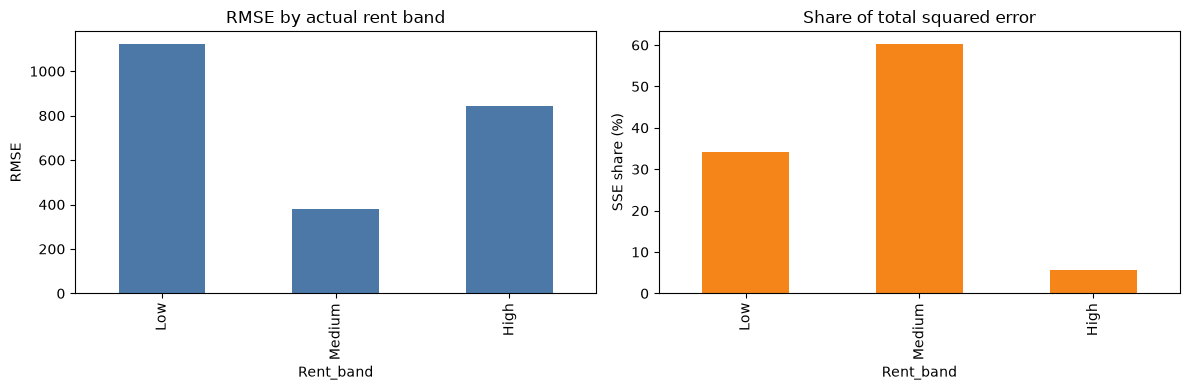

In [4]:
error_table["Rent_band"] = pd.cut(
    error_table["Actual"], [-np.inf, 2000, 4500, np.inf],
    labels=["Low", "Medium", "High"]
)
rent_band_summary = error_summary(error_table, "Rent_band")
display(rent_band_summary)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
rent_band_summary.loc[["Low", "Medium", "High"], "RMSE"].plot.bar(
    ax=axes[0], color="#4c78a8"
)
axes[0].set_title("RMSE by actual rent band")
axes[0].set_ylabel("RMSE")
rent_band_summary.loc[["Low", "Medium", "High"], "SSE_share_pct"].plot.bar(
    ax=axes[1], color="#f58518"
)
axes[1].set_title("Share of total squared error")
axes[1].set_ylabel("SSE share (%)")
plt.tight_layout()
plt.show()

In [5]:
error_table.sort_values(["Squared_error"], ascending=False).head()

,TOWN,STREET,FLAT_TYPE,FLAT_MODEL,HDB_SUBZONE,HDB_PLANNING_AREA,LOCATION_KEY,FLOOR_AREA_SQM,LEASE_COMMENCE_DATE,HDB_LATITUDE,...,MONTH_INDEX,BUILDING_AGE,MONTHLY_RENT,Actual,Predicted,Residual,Absolute_error,Squared_error,Absolute_percentage_error,Rent_band
147171,bukit merah,depot road,5-room,improved,depot road,bukit merah,bukit merah|112a|depot road,115.0,2006.0,1.281476,...,50,19.0,650,650,3980.531803,-3330.531803,3330.531803,1.109244e+07,512.389508,Low
116969,bedok,bedok north street 3,5-room,adjoined flat,bedok north,bedok,bedok|527|bedok north street 3,136.0,1979.0,1.333911,...,39,45.0,800,800,4020.505654,-3220.505654,3220.505654,1.037166e+07,402.563207,Low
137444,ang mo kio,ang mo kio avenue 6,5-room,improved,ang mo kio town centre,ang mo kio,ang mo kio|714|ang mo kio avenue 6,119.0,1980.0,1.371096,...,46,44.0,750,750,3719.750444,-2969.750444,2969.750444,8.819418e+06,395.966726,Low
123289,queenstown,dawson road,4-room,premium apartment loft,margaret drive,queenstown,queenstown|89|dawson road,97.0,2016.0,1.295463,...,41,8.0,1300,1300,4202.825296,-2902.825296,2902.825296,8.426395e+06,223.294254,Low
121557,queenstown,holland drive,5-room,adjoined flat,holland drive,queenstown,queenstown|13|holland drive,147.0,1975.0,1.309360,...,41,49.0,3200,3200,6095.633799,-2895.633799,2895.633799,8.384695e+06,90.488556,Medium


We can see that low-rent samples are only about 6% of validation rows but still contributed about 34% of total squared error. This means the low-rent band has much higher per-row error

Some possible causes of this are:

1. Regression toward the mean: CatBoost may predict closer to the dominant medium-rent range, overpredicting unusually cheap flats.

2. Sparse or unusual low-rent cases: low rents may correspond to rare flat types, locations, furnishing conditions, or atypical records with few similar training examples.

3. Conflicting entries: inconsistent rent records may be more influential in the low band. We will come back to this later in the notebook.

4. Missing explanatory variables: the data may not capture unit-level factors such as condition, floor, etc that may explain unusually low rents.

Among the five rows with the largest errors, four belong to the low-rent band. These may be potential outliers, as their low rents are inconsistent with characteristics such as being 5-room or executive flats, suggesting that some rent records may be erroneous.

## 5. Error by category and category imbalance

We group samples by categories in some categorical features and see which ones have the highest error.

In [6]:
CATEGORY_COLUMNS = ["TOWN", "FLAT_TYPE", "FLAT_MODEL", "APPROVAL_YEAR"]

category_summaries = {}
for column in CATEGORY_COLUMNS:
    summary = error_summary(error_table, column).copy()
    category_summaries[column] = summary
    print(f"\n=== {column}: highest SSE contribution ===")
    display(summary.head())
    print(f"\n=== {column}: highest RMSE per row ===")
    display(summary.sort_values("RMSE", ascending=False).head())



=== TOWN: highest SSE contribution ===


,Rows,MAE,RMSE,Mean_residual,SSE,Row_share_pct,SSE_share_pct
TOWN,,,,,,,
jurong west,2467,439.626037,574.079253,90.425530,8.130418e+08,7.016895,10.432280
bukit merah,2016,379.540764,514.463869,53.786763,5.335809e+08,5.734115,6.846470
tampines,2258,342.737630,464.774551,28.623447,4.877627e+08,6.422436,6.258569
bedok,2081,355.505966,469.302325,27.742558,4.583292e+08,5.918994,5.880901
kallang/whampoa,1365,407.193817,534.703074,62.557886,3.902636e+08,3.882473,5.007540



=== TOWN: highest RMSE per row ===


,Rows,MAE,RMSE,Mean_residual,SSE,Row_share_pct,SSE_share_pct
TOWN,,,,,,,
bukit timah,93,475.087382,637.701107,105.733429,3.781963e+07,0.264520,0.485270
jurong west,2467,439.626037,574.079253,90.425530,8.130418e+08,7.016895,10.432280
kallang/whampoa,1365,407.193817,534.703074,62.557886,3.902636e+08,3.882473,5.007540
bishan,760,382.862225,520.673912,59.388310,2.060370e+08,2.161670,2.643697
bukit merah,2016,379.540764,514.463869,53.786763,5.335809e+08,5.734115,6.846470



=== FLAT_TYPE: highest SSE contribution ===


,Rows,MAE,RMSE,Mean_residual,SSE,Row_share_pct,SSE_share_pct
FLAT_TYPE,,,,,,,
4-room,12851,351.762616,475.418898,30.855987,2.904623e+09,36.552136,37.269727
3-room,11611,334.174645,440.412933,26.701050,2.252111e+09,33.025201,28.897226
5-room,7963,349.269922,484.455306,26.114691,1.868892e+09,22.649184,23.980076
executive,1778,421.292213,572.860217,69.392182,5.834842e+08,5.057170,7.486787
2-room,941,319.161092,440.621966,20.741069,1.826930e+08,2.676489,2.344166


... (6 outputs left out)


=== APPROVAL_YEAR: highest SSE contribution ===


,Rows,MAE,RMSE,Mean_residual,SSE,Row_share_pct,SSE_share_pct
APPROVAL_YEAR,,,,,,,
2024,26234,350.743064,475.876019,20.742168,5.940899e+09,74.617441,76.228707
2025,8924,339.974036,455.631163,57.567100,1.852620e+09,25.382559,23.771293



=== APPROVAL_YEAR: highest RMSE per row ===


,Rows,MAE,RMSE,Mean_residual,SSE,Row_share_pct,SSE_share_pct
APPROVAL_YEAR,,,,,,,
2024,26234,350.743064,475.876019,20.742168,5.940899e+09,74.617441,76.228707
2025,8924,339.974036,455.631163,57.567100,1.852620e+09,25.382559,23.771293


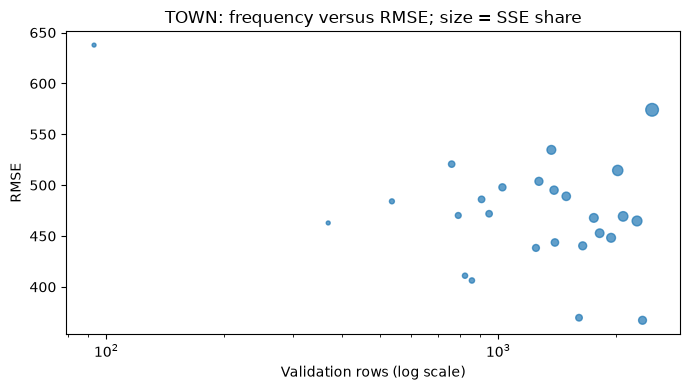

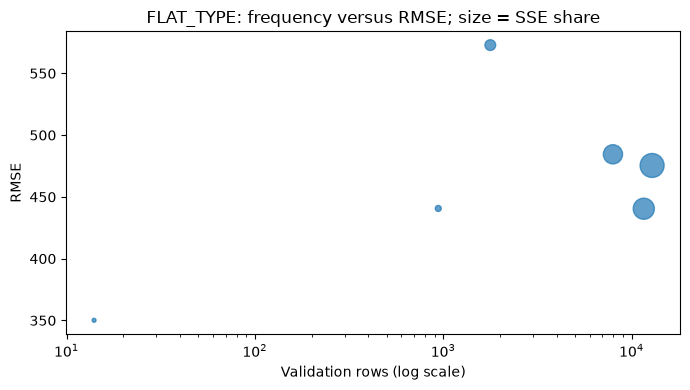

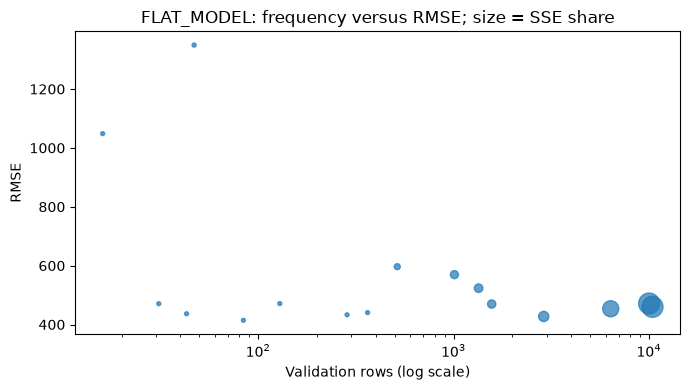

In [7]:
# Frequency versus error for the main categorical features.
for column in ["TOWN", "FLAT_TYPE", "FLAT_MODEL"]:
    plot_data = category_summaries[column].reset_index()
    plot_data = plot_data.loc[plot_data["Rows"] >= 10].copy()
    plt.figure(figsize=(7, 4))
    plt.scatter(
        plot_data["Rows"], plot_data["RMSE"],
        s=np.maximum(plot_data["SSE_share_pct"], 1) * 8, alpha=0.7
    )
    plt.xscale("log")
    plt.xlabel("Validation rows (log scale)")
    plt.ylabel("RMSE")
    plt.title(f"{column}: frequency versus RMSE; size = SSE share")
    plt.tight_layout()
    plt.show()

### Interpretation of category frequency and error

The plots should be read using two different measures:
 `SSE_share_pct` reflects total contribution to validation error, so common categories can dominate it simply because they contain many rows. For example, Jurong West contributes the largest share of Town-level squared error (about 10.4%), but it also has the largest validation count (2,467 rows). This is consistent with the EDA, where Jurong West is the most common Town in the full training data (~10k rows). Its large total contribution is therefore partly a volume effect.

`RMSE` measures error per row and gives a clearer view of category difficulty. Bukit Timah has the highest Town-level RMSE, having only 93 validation rows. EDA shows that it is also highly under-represented in the full data, with only 438 rows. This suggests that less frequently observed Towns can have larger per-row errors even when their total error contribution is small.

A similar pattern appears for Flat Model. Common models such as 'improved' (44,008 EDA rows; 10,018 validation rows) and 'model a' (42,745 EDA rows; 10,425 validation rows) contribute the most total squared error because they are frequent. However, adjoined flat has the highest Flat Model RMSE (about 1,078) with only 47 validation rows, compared with 218 rows in the EDA. Rare models such as terrace, 3gen, and premium maisonette are also sparsely represented, so their RMSE estimates could be unstable.

For Flat Type, the same distinction is visible but weaker. The common 4-room, 3-room, and 5-room categories dominate total error because of frequency. Executive flats have the highest Flat Type RMSE (about 422) and are less common (8,234 EDA rows; 1,778 validation rows). So their greater per-row error may reflect lower representation or higher difficulty.

Overall, the results suggest that under-represented categories generally have higher per-row error, while well-represented categories account for more total error because of their larger sample sizes. But we cannot conclude that low sample size is the only reason for their higher errors, they can be caused by other factors, such as unusual rent values, or data-quality issues. It is more concerning if a rare category has a large percentage contribution to total error. 

## 6. Revisit conflicting entries

Following `Data_cleaning.ipynb`, a conflict group is formed by grouping on every non-target column. A group is conflicting when it contains more than one distinct rent. This does not prove that the data is erroneous: the unit identifier is unavailable, so different units may share the same recorded features.

Group IDs are created across all labeled rows for diagnostics only. They are not model features.

In [8]:
CONFLICT_FEATURES = [c for c in train.columns if c != TARGET]
conflict_keys = train[CONFLICT_FEATURES].copy()
all_group_ids = conflict_keys.groupby(
    CONFLICT_FEATURES, dropna=False, sort=False
).ngroup()

all_with_groups = train.copy()
all_with_groups["_Conflict_group"] = all_group_ids.to_numpy()

conflict_summary = all_with_groups.groupby("_Conflict_group")[TARGET].agg(
    Rows="size", Distinct_rents="nunique", Min_rent="min", Max_rent="max",
    Rents=lambda values: sorted(values.unique().tolist()),
)
conflict_summary["Rent_spread"] = (
    conflict_summary["Max_rent"] - conflict_summary["Min_rent"]
)
conflict_summary = conflict_summary.loc[
    conflict_summary["Distinct_rents"] > 1
].sort_values(["Rent_spread", "Rows"], ascending=False)

conflict_group_ids = set(conflict_summary.index)
error_table["_Conflict_group"] = all_with_groups.loc[
    error_table.index, "_Conflict_group"
]
error_table["Is_conflicting"] = error_table["_Conflict_group"].isin(
    conflict_group_ids
)
error_table["Conflict_rent_spread"] = error_table["_Conflict_group"].map(
    conflict_summary["Rent_spread"]
)
error_table["Conflict_status"] = np.select(
    [
        ~error_table["Is_conflicting"],
        error_table["Conflict_rent_spread"] <= 500,
        error_table["Conflict_rent_spread"] > 500,
    ],
    [
        "Non-conflicting",
        "Conflicting: spread <= 500",
        "Conflicting: spread > 500",
    ],
    default="Non-conflicting",
)

print(f"Conflict groups: {len(conflict_summary):,}")
print(
    f"Rows in conflict groups: {error_table['Is_conflicting'].sum():,} "
    f"of {len(error_table):,} validation rows"
)
display(conflict_summary.head(10))
display(error_summary(error_table, "Conflict_status"))

Conflict groups: 17,869
Rows in conflict groups: 9,114 of 35,158 validation rows


,Rows,Distinct_rents,Min_rent,Max_rent,Rents,Rent_spread
_Conflict_group,,,,,,
73623,3,3,1500,5200,"[1500, 5000, 5200]",3700
103401,3,3,950,4500,"[950, 1300, 4500]",3550
82157,2,2,1800,5300,"[1800, 5300]",3500
73232,2,2,600,3800,"[600, 3800]",3200
73002,2,2,1300,4300,"[1300, 4300]",3000
73654,2,2,1500,4500,"[1500, 4500]",3000
95567,2,2,1000,4000,"[1000, 4000]",3000
99781,2,2,1500,4500,"[1500, 4500]",3000
108841,2,2,1200,4200,"[1200, 4200]",3000


,Rows,MAE,RMSE,Mean_residual,SSE,Row_share_pct,SSE_share_pct
Conflict_status,,,,,,,
Non-conflicting,26044,346.810074,471.861571,31.074191,5.798784e+09,74.077024,74.405203
Conflicting: spread > 500,3922,477.516725,609.315379,-84.529926,1.456102e+09,11.155356,18.683501
Conflicting: spread <= 500,5192,256.197937,322.091451,111.731313,5.386332e+08,14.767620,6.911296


Some groups have very large spreads, such as rents of SGD 1,500, SGD 5,000, and SGD 5,200 for otherwise identical recorded features.

The second table compares model error: high-spread conflict rows represent only about 11.2% of validation rows but contribute about 18.6% of total squared error. This suggests that highly inconsistent target values are a big source of model error.

Also, the negative mean residual for high-spread conflicts means the model tends to overpredict these rows on average. With this observstion, we can try one experiment where we pre-process high-spread groups to retain only their highest rent observation.

## 7. Sensitivity experiment: filter large-spread conflicts

For training conflict groups with rent spread greater than SGD 500, retain only rows with the highest rent (this is not based on any theoretical analysis, only by looking at a few rows). It is not the default cleaning strategy because it may remove valid observations and bias the target upward. The validation set remains unchanged.

In [9]:
SPREAD_THRESHOLD = 500

def filter_conflicting_rents(
    df, conflict_cols, threshold_sgd, rent_col=TARGET
):
    result = df.copy()
    rent_values = pd.to_numeric(result[rent_col], errors="coerce")
    grouped_rent = rent_values.groupby(
        [result[col] for col in conflict_cols], dropna=False
    )
    group_min = grouped_rent.transform("min")
    group_max = grouped_rent.transform("max")
    is_conflicting = (group_max - group_min) > threshold_sgd
    keep_rows = ~is_conflicting | rent_values.eq(group_max)
    return result.loc[keep_rows].reset_index(drop=True)

filtered_training = filter_conflicting_rents(
    training_data, CONFLICT_FEATURES, SPREAD_THRESHOLD, TARGET
)
filtered_model = CatBoostRegressor(
    iterations=cb_best_iterations, **CB_PARAMS
)
filtered_model.fit(
    make_catboost_features(filtered_training),
    filtered_training[TARGET],
    cat_features=CATBOOST_CATEGORICAL,
    verbose=200,
)
filtered_predictions = filtered_model.predict(X_cb_val)
sensitivity = pd.DataFrame({
    "Model": ["Original CatBoost", "Conflict-filtered CatBoost"],
    "Training_rows": [len(training_data), len(filtered_training)],
    "Validation_MAE": [
        mean_absolute_error(y_cb_val, cb_val_predictions),
        mean_absolute_error(y_cb_val, filtered_predictions),
    ],
    "Validation_RMSE": [
        np.sqrt(mean_squared_error(y_cb_val, cb_val_predictions)),
        np.sqrt(mean_squared_error(y_cb_val, filtered_predictions)),
    ],
})
display(sensitivity)

0:	learn: 704.6933641	total: 21.6ms	remaining: 23.6s
200:	learn: 465.4266821	total: 3.67s	remaining: 16.3s
400:	learn: 460.2510310	total: 7.99s	remaining: 13.8s
600:	learn: 455.6508789	total: 12.3s	remaining: 10.1s
800:	learn: 452.0308829	total: 16.7s	remaining: 6.11s
1000:	learn: 448.8605283	total: 21.1s	remaining: 1.96s
1093:	learn: 447.6952582	total: 23.2s	remaining: 0us


,Model,Training_rows,Validation_MAE,Validation_RMSE
0,Original CatBoost,114683,348.009609,470.819801
1,Conflict-filtered CatBoost,107383,340.062481,470.573003


The purpose of this experiment is not to claim that the lower-rent rows are wrong. We just want to check if model performance changes if large-spread conflict groups are made more consistent.

The tiny improvement in RMSE suggests that high-spread conflicts may add noise to training. But, our filtering rule may also bias the model upward because it systematically keeps the highest rent. Therefore, this should not automatically become the final preprocessing rule.

## 8. Export data tables

In [10]:
OUTPUT_DIR = ROOT / "derived" / "error_analysis"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

error_table.to_csv(OUTPUT_DIR / "catboost_validation_errors.csv", index=True)
rent_band_summary.to_csv(OUTPUT_DIR / "error_by_rent_band.csv")
conflict_summary.to_csv(OUTPUT_DIR / "conflict_group_summary.csv")

for column, summary in category_summaries.items():
    summary.to_csv(OUTPUT_DIR / f"error_by_{column.lower()}.csv")

print(f"Exported diagnostic tables to {OUTPUT_DIR}")

Exported diagnostic tables to /Users/apple/Documents/modules/CS5228/project repo/cs5228_team26/derived/error_analysis
